# Final screening of 476 single-atom catalysts for NRR

Sequence (following Das et al., ACS AMI 2024, adapted to SACs and to UMA data):

1. **Stage 1, stability:** dissolution potential U_diss > 0 and formation energy E_f < 0, both inside a ±0.7 eV error band on E_f.
2. **Stage 2, activity:** ΔG(*N₂ → *NNH) between 0 and 0.20 eV (Das's first criterion).
3. **Stage 3, N₂ activation:** ΔE*N₂ between −1.40 and −0.80 eV (Das's second criterion).
4. **Stage 4, selectivity:** U_L(NRR) > U_L(HER), where U_L(HER) = −|ΔG*H|.

UMA (zero-shot) supplies the energies for all 476 catalysts. Its absolute adsorption energies carry a per-catalyst offset, so each Das quantity is
corrected by a **Δ-learning model**: an ML model trained on Xu's DFT values, with the UMA value and element/site descriptors as inputs.
Every filter gives two verdicts:
- **confident:** the value is inside the window;
- **possible:** the value is inside the window widened by the model's cross-validated error.

Inputs (same folder): `UMA_476_full.csv`, `xu_reference.csv`, `metal_descriptors.csv`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold, LeaveOneGroupOut, LeaveOneOut
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
df = pd.read_csv('UMA_476_full.csv')
ref = pd.read_csv('xu_reference.csv')
mdesc = pd.read_csv('metal_descriptors.csv')
df = df.drop(columns=[c for c in ['U0_diss_V', 'n_e'] if c in df]).merge(mdesc, on='Metal', how='left')
FAM = {'S/N (Xu)': '#2a78d6', 'N/C double vacancy': '#eb6834', 'single vacancy': '#1baf7a'}
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
print(df.shape, df.family.value_counts().to_dict())

(476, 80) {'S/N (Xu)': 196, 'N/C double vacancy': 168, 'single vacancy': 112}


## Stage 1: stability (dissolution potential)

U_diss = U°diss(M) − E_f / n_e, with E_f = E(M@support) − E(support) − μ_M(bulk). This is Das's eq. 3 (from Greeley & Nørskov) written for a SAC.

- **Inputs:**
  - U°diss and n_e: standard dissolution potential of the bulk metal (CRC). W and Os use oxide couples (WO₂/W, OsO₄/Os).
  - E_f: computed by UMA, then calibrated to Xu's PBE values (E_f,cal = 0.832 E_f,UMA − 0.208; MAE 0.69 eV, n = 153).
- **Stable** means U_diss > 0 **and** E_f < 0, for every E_f in [E_f,cal − 0.7, E_f,cal + 0.7].
  - U_diss > 0: the metal does not dissolve at 0 V vs RHE.
  - E_f < 0: the metal prefers the site over clustering. This is Das's binding-vs-cohesive check (their Table S6), applied to every catalyst.

In [2]:
df['U_diss_check'] = df.U0_diss_V - df.Ef_cal / df.n_e
assert np.allclose(df.U_diss_check, df.U_diss_cal, atol=2e-3, equal_nan=True)  # inputs agree up to rounding
site_ok = df.status_bare == 'ok'
das_only = site_ok & (df.U_diss_cal > 0)
S1 = site_ok & (df.stability == 'stable')
df['S1'] = S1
print('metal stays in its site:', site_ok.sum())
print('Das rule only (U_diss > 0):', das_only.sum(), '| ours (U_diss > 0 and Ef < 0, ±0.7 eV band):', S1.sum())
print(df[S1].groupby('family').size().to_dict())
ex = df[df.SAC.isin(['Os@N2C2-OPP', 'Mo@N4', 'Pt@N4', 'Pt@S4'])][['SAC', 'Ef_cal', 'U0_diss_V', 'n_e', 'U_diss_cal', 'stability']]
print(ex.round(3).to_string(index=False))

metal stays in its site: 459
Das rule only (U_diss > 0): 210 | ours (U_diss > 0 and Ef < 0, ±0.7 eV band): 97
{'N/C double vacancy': 79, 'S/N (Xu)': 8, 'single vacancy': 10}
        SAC  Ef_cal  U0_diss_V  n_e  U_diss_cal stability
      Mo@N4  -0.207     -0.200    3      -0.131 uncertain
      Pt@N4  -1.525      1.180    2       1.943    stable
      Pt@S4   1.062      1.180    2       0.649  unstable
Os@N2C2-OPP  -1.364      0.838    8       1.009    stable


## Δ-learning models (trained on Xu's DFT)

A single helper trains each model and compares four candidates:

| Model | Inputs |
|---|---|
| UMA-linear | UMA value only (a straight-line calibration) |
| Ridge | UMA value + descriptors |
| KRR | UMA value + descriptors |
| GBR | UMA value + descriptors |

- **Descriptors:** group, period, Nd, χ_M, IE1, E_coh, n_S. Site descriptors such as n_C and CN are constant in Xu's data, so the UMA value has to carry the coordination effect.
- **Model choice:** by leave-one-support-out MAE (7 folds), which mimics predicting a support the model has not seen. Hyper-parameters are tuned inside each fold.

In [3]:
DESC = ['group', 'period', 'Nd', 'chi_M', 'IE1', 'Ecoh', 'n_S']
def candidates():
    return {
        'UMA-linear': (LinearRegression(), None, 'uma_only'),
        'Ridge': (make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': [0.1, 1, 3, 10, 30]}, 'all'),
        'KRR': (make_pipeline(StandardScaler(), KernelRidge(kernel='rbf')),
                {'kernelridge__alpha': [0.03, 0.1, 0.3, 1], 'kernelridge__gamma': [0.01, 0.03, 0.1, 0.3]}, 'all'),
        'GBR': (GradientBoostingRegressor(random_state=0, subsample=0.8),
                {'n_estimators': [100, 300], 'max_depth': [2, 3], 'learning_rate': [0.03, 0.1]}, 'all'),
    }

def delta_model(train, target, uma_cols, groups, name):
    X_all = train[uma_cols + DESC].values; y = train[target].values; Xu = train[uma_cols].values
    res, preds = [], {}
    for mname, (est, grid, kind) in candidates().items():
        X = Xu if kind == 'uma_only' else X_all
        p = np.full(len(y), np.nan)
        for tr, te in LeaveOneGroupOut().split(X, y, groups):
            m = GridSearchCV(est, grid, cv=KFold(5, shuffle=True, random_state=0), scoring='neg_mean_absolute_error') if grid else est
            m.fit(X[tr], y[tr]); p[te] = m.predict(X[te])
        preds[mname] = p
        res.append(dict(target=name, model=mname, n=len(y), MAE=np.abs(p - y).mean(), r=np.corrcoef(p, y)[0, 1],
                        raw_UMA_MAE=np.abs(train[uma_cols[0]].values - y).mean()))
    res = pd.DataFrame(res); best = res.sort_values('MAE').iloc[0]
    est, grid, kind = candidates()[best.model]
    X = Xu if kind == 'uma_only' else X_all
    final = GridSearchCV(est, grid, cv=KFold(5, shuffle=True, random_state=0), scoring='neg_mean_absolute_error') if grid else est
    final.fit(X, y)
    return res, best, preds[best.model], (final, kind)

def predict(model, frame, uma_cols):
    final, kind = model
    X = frame[uma_cols].values if kind == 'uma_only' else frame[uma_cols + DESC].values
    return final.predict(X)

xu = df[df.family == 'S/N (Xu)'].merge(ref.drop(columns=[c for c in ['Metal', 'Support', 'U0_diss_V', 'n_e', 'Ecoh_eV'] if c in ref]), on='SAC', how='inner')

### Model A: ΔG(*N₂ → *NNH), end-on (stage 2)
Trained on the Xu catalysts where *N₂ and *NNH stayed bound in UMA.

In [4]:
okN = (df.status_N2_end == 'ok') & (df.status_NNH_end == 'ok') & site_ok
trA = xu[(xu.status_N2_end == 'ok') & (xu.status_NNH_end == 'ok') & (xu.status_bare == 'ok')].dropna(subset=['xu_dG_N2_to_NNH_end', 'dG_N2_to_NNH_end', 'dE_N2_end'])
resA, bestA, cvA, mA = delta_model(trA, 'xu_dG_N2_to_NNH_end', ['dG_N2_to_NNH_end', 'dE_N2_end'], trA.Support.values, 'dG N2->NNH')
print(resA.round(3).to_string(index=False)); print('chosen:', bestA.model)
ERR_A = bestA.MAE
df['step1_ml'] = np.nan
df.loc[okN, 'step1_ml'] = predict(mA, df[okN], ['dG_N2_to_NNH_end', 'dE_N2_end'])

    target      model  n   MAE     r  raw_UMA_MAE
dG N2->NNH UMA-linear 85 0.260 0.518        0.273
dG N2->NNH      Ridge 85 0.243 0.631        0.273
dG N2->NNH        KRR 85 0.241 0.630        0.273
dG N2->NNH        GBR 85 0.207 0.752        0.273
chosen: GBR


### Model B: ΔE*N₂, end-on (stage 3)

In [5]:
okE = (df.status_N2_end == 'ok') & site_ok
trB = xu[(xu.status_N2_end == 'ok') & (xu.status_bare == 'ok')].dropna(subset=['xu_dE_N2_end', 'dE_N2_end', 'dE_NNH_end'])
resB, bestB, cvB, mB = delta_model(trB, 'xu_dE_N2_end', ['dE_N2_end', 'dE_NNH_end'], trB.Support.values, 'dE N2')
print(resB.round(3).to_string(index=False)); print('chosen:', bestB.model)
ERR_B = bestB.MAE
df['dEN2_ml'] = np.nan
okE2 = okE & df.dE_NNH_end.notna()
df.loc[okE2, 'dEN2_ml'] = predict(mB, df[okE2], ['dE_N2_end', 'dE_NNH_end'])

target      model  n   MAE     r  raw_UMA_MAE
 dE N2 UMA-linear 86 0.210 0.526        0.544
 dE N2      Ridge 86 0.179 0.725        0.544
 dE N2        KRR 86 0.188 0.714        0.544
 dE N2        GBR 86 0.175 0.739        0.544
chosen: GBR


### Model C: ΔG*H (HER)
Xu's DFT ΔG*H exists for only 26 S/N catalysts, so this model is validated by leave-one-out and uses fewer inputs.

In [6]:
okH = (df.status_H == 'ok') & site_ok
trC = xu[(xu.status_H == 'ok') & (xu.status_bare == 'ok')].dropna(subset=['xu_dG_H', 'dG_H*'])
DESC_FULL = DESC
DESC = ['group', 'Nd', 'chi_M', 'n_S']          # small data -> fewer inputs
resC, bestC, cvC, mC = delta_model(trC, 'xu_dG_H', ['dG_H*'], np.arange(len(trC)), 'dG*H')
print(resC.round(3).to_string(index=False)); print('chosen:', bestC.model)
ERR_C = bestC.MAE
df['dGH_ml'] = np.nan
df.loc[okH, 'dGH_ml'] = predict(mC, df[okH], ['dG_H*'])
DESC = DESC_FULL

target      model  n   MAE     r  raw_UMA_MAE
  dG*H UMA-linear 26 0.123 0.656        0.269
  dG*H      Ridge 26 0.103 0.727        0.269
  dG*H        KRR 26 0.106 0.698        0.269
  dG*H        GBR 26 0.130 0.629        0.269
chosen: Ridge


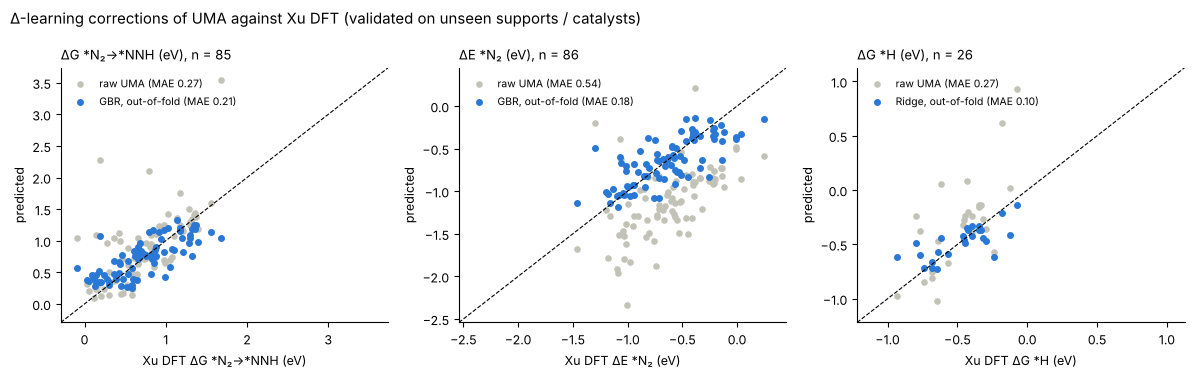

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, (tr, cv, tgt, uma, best, lab) in zip(ax, [
        (trA, cvA, 'xu_dG_N2_to_NNH_end', 'dG_N2_to_NNH_end', bestA, 'ΔG *N₂→*NNH (eV)'),
        (trB, cvB, 'xu_dE_N2_end', 'dE_N2_end', bestB, 'ΔE *N₂ (eV)'),
        (trC, cvC, 'xu_dG_H', 'dG_H*', bestC, 'ΔG *H (eV)')]):
    y = tr[tgt].values
    a.scatter(y, tr[uma].values, s=14, c='#c3c2b7', label=f'raw UMA (MAE {np.abs(tr[uma].values - y).mean():.2f})')
    a.scatter(y, cv, s=16, c='#2a78d6', label=f'{best.model}, out-of-fold (MAE {best.MAE:.2f})')
    lo, hi = min(y.min(), cv.min(), tr[uma].min()) - 0.2, max(y.max(), cv.max(), tr[uma].max()) + 0.2
    a.plot([lo, hi], [lo, hi], 'k--', lw=0.8); a.set_xlim(lo, hi); a.set_ylim(lo, hi)
    a.set_xlabel('Xu DFT ' + lab); a.set_ylabel('predicted'); a.legend(fontsize=7.5, frameon=False, loc='upper left')
    a.set_title(f'{lab}, n = {len(y)}', fontsize=9.5, loc='left')
fig.suptitle('Δ-learning corrections of UMA against Xu DFT (validated on unseen supports / catalysts)', x=0.01, ha='left')
fig.tight_layout(); fig.savefig('fig_delta_models.png', dpi=170); plt.show()

## Stages 2 to 4

- **Stage 2:** corrected ΔG(*N₂→*NNH) in [0, 0.20] eV (confident), or in [−err, 0.20 + err] (possible).
- **Stage 3:** corrected ΔE*N₂ in [−1.40, −0.80] eV (confident), or in [−1.40 − err, −0.80 + err] (possible).
- **Stage 4, U_L(NRR):**
  - Built from all proton–electron steps of the best pathway (distal or alternating), with the first step replaced by its corrected value.
  - NH₃ release is pinned to the experimental free energy.
  - U_L(HER) = −|ΔG*H, corrected|.
  - Confident if U_L(NRR) > U_L(HER). Possible if U_L(NRR) + 0.3 > U_L(HER) − err_H.

In [8]:
G_NH3 = -0.17
PATHS = {'distal': (['N2_end', 'NNH_end', 'NNH2', 'N', 'NH', 'NH2', 'NH3'], [0, 0, 0, 1, 1, 1, 1]),
         'alternating': (['N2_end', 'NNH_end', 'NHNH', 'NHNH2', 'NH2NH2', 'NH2', 'NH3'], [0, 0, 0, 0, 0, 1, 1])}
def ul_nrr(r):
    best = None
    for p, (seq, out) in PATHS.items():
        if not all(r.get(f'status_{k}') == 'ok' and pd.notna(r.get(f'dG_{k}')) for k in seq):
            continue
        states = [r[f'dG_{k}'] + n * G_NH3 for k, n in zip(seq, out)]
        steps = list(np.diff(states))                    # proton-electron steps only
        if pd.notna(r.step1_ml):
            steps[0] = r.step1_ml                        # corrected *N2 -> *NNH
        k = int(np.argmax(steps)); ul = -steps[k]
        if best is None or ul > best[0]:
            best = (ul, p, f'{seq[k]}->{seq[k+1]}')
    return pd.Series(best if best else (np.nan, None, None), index=['UL_NRR', 'path', 'PDS'])
df = pd.concat([df.drop(columns=[c for c in ['UL_NRR', 'path', 'PDS'] if c in df]), df.apply(ul_nrr, axis=1)], axis=1)
df['UL_HER'] = -df.dGH_ml.abs()
eA, eB, eC = ERR_A, ERR_B, ERR_C
c2 = df.step1_ml.between(0, 0.20);              p2 = df.step1_ml.between(-eA, 0.20 + eA)
c3 = df.dEN2_ml.between(-1.40, -0.80);          p3 = df.dEN2_ml.between(-1.40 - eB, -0.80 + eB)
c4 = df.UL_NRR > df.UL_HER;                     p4 = (df.UL_NRR + 0.3) > (df.UL_HER - eC)
stages = [('All catalysts', pd.Series(True, index=df.index), pd.Series(True, index=df.index)),
          ('Metal stays in its site', site_ok, site_ok),
          ('Stage 1: stable (U_diss > 0, Ef < 0)', S1, S1)]
stages.append(('Stage 2: ΔG *N2→*NNH 0–0.20 eV', stages[-1][1] & c2, stages[-1][2] & p2))
stages.append(('Stage 3: ΔE *N2 −1.40 to −0.80 eV', stages[-1][1] & c3, stages[-1][2] & p3))
stages.append(('Stage 4: U_L(NRR) > U_L(HER)', stages[-1][1] & c4, stages[-1][2] & p4))
fun = pd.DataFrame([dict(stage=n, confident=int(c.sum()), possible=int(p.sum()),
                         **{f'possible {f}': int((p & (df.family == f)).sum()) for f in FAM}) for n, c, p in stages])
print(f'errors used: stage 2 ±{eA:.2f} eV, stage 3 ±{eB:.2f} eV, HER ±{eC:.2f} eV')
print(fun.to_string(index=False))
df['final_confident'] = stages[-1][1]; df['final_possible'] = stages[-1][2]

errors used: stage 2 ±0.21 eV, stage 3 ±0.18 eV, HER ±0.10 eV
                               stage  confident  possible  possible S/N (Xu)  possible N/C double vacancy  possible single vacancy
                       All catalysts        476       476                196                          168                      112
             Metal stays in its site        459       459                185                          168                      106
Stage 1: stable (U_diss > 0, Ef < 0)         97        97                  8                           79                       10
      Stage 2: ΔG *N2→*NNH 0–0.20 eV          0         3                  0                            3                        0
   Stage 3: ΔE *N2 −1.40 to −0.80 eV          0         3                  0                            3                        0
        Stage 4: U_L(NRR) > U_L(HER)          0         3                  0                            3                        0


### Threshold sensitivity
Das's 0–0.20 eV window was set for metal nanoclusters. Even Xu's own DFT puts only 10 of their 91 S/N catalysts inside it.
Xu's screen for these same SACs used ΔG(*N₂→*N₂H) < 0.55 eV, so the cell below repeats stages 2–4 with that limit as a sensitivity check.

In [9]:
rows = []
for lab, hi in (('Das, 0.20 eV', 0.20), ('Das + model error', 0.20 + eA), ('Xu 2025, 0.55 eV', 0.55)):
    a = S1 & df.step1_ml.between(-eA, hi); b = a & p3; c = b & p4; cc = b & c4
    rows.append(dict(stage2_limit=lab, after_stage2=int(a.sum()), after_stage3=int(b.sum()), after_HER_possible=int(c.sum()),
                     after_HER_confident=int(cc.sum()), catalysts=', '.join(sorted(df[c].SAC))))
print(pd.DataFrame(rows).to_string(index=False))

     stage2_limit  after_stage2  after_stage3  after_HER_possible  after_HER_confident                                                   catalysts
     Das, 0.20 eV             0             0                   0                    0                                                            
Das + model error             3             3                   3                    2                       Mo@N2C2-PEN, Re@N2C2-OPP, Re@N2C2-PEN
 Xu 2025, 0.55 eV             5             5                   5                    3 Mo@N2C2-OPP, Mo@N2C2-PEN, Re@N1C3, Re@N2C2-OPP, Re@N2C2-PEN


### Do the models agree on the new families?
The models were trained on S/N sites only, so applying them to N/C and single-vacancy sites is an extrapolation. Below, all four candidate models predict
the corrected first step for the stable catalysts. Their spread is a direct measure of that extrapolation risk.

In [10]:
stab = df[S1 & okN].copy()
for mname, (est, grid, kind) in candidates().items():
    cols_ = ['dG_N2_to_NNH_end', 'dE_N2_end'] if kind == 'uma_only' else ['dG_N2_to_NNH_end', 'dE_N2_end'] + DESC
    m = GridSearchCV(est, grid, cv=KFold(5, shuffle=True, random_state=0), scoring='neg_mean_absolute_error') if grid else est
    m.fit(trA[cols_].values, trA['xu_dG_N2_to_NNH_end'].values); stab[mname] = m.predict(stab[cols_].values)
names = list(candidates())
stab['mean_4'] = stab[names].mean(axis=1); stab['spread_4'] = stab[names].std(axis=1)
print('median spread between models, by family (eV):', stab.groupby('family').spread_4.median().round(2).to_dict())
print(stab.sort_values('mean_4')[['SAC', 'dG_N2_to_NNH_end'] + names + ['mean_4', 'spread_4']].head(8).round(2).to_string(index=False))

median spread between models, by family (eV): {'N/C double vacancy': 0.18, 'S/N (Xu)': 0.2, 'single vacancy': 0.18}
        SAC  dG_N2_to_NNH_end  UMA-linear  Ridge  KRR  GBR  mean_4  spread_4
Re@N2C2-PEN              0.44        0.49   0.57 0.16 0.35    0.39      0.18
Re@N2C2-OPP              0.39        0.49   0.54 0.24 0.33    0.40      0.14
Mo@N2C2-PEN              0.46        0.55   0.61 0.33 0.37    0.46      0.14
    Re@N1C3              0.65        0.60   0.63 0.30 0.50    0.51      0.15
Mo@N2C2-OPP              0.60        0.60   0.67 0.34 0.50    0.53      0.14
Os@N2C2-PEN              0.53        0.54   0.60 0.54 0.81    0.62      0.13
Os@N2C2-OPP              0.48        0.56   0.57 0.74 0.75    0.65      0.10
   Re@SV-C3              1.09        0.81   0.79 0.48 0.55    0.66      0.16


In [11]:
cols = ['SAC', 'family', 'Ef_cal', 'U_diss_cal', 'step1_ml', 'dEN2_ml', 'UL_NRR', 'path', 'PDS', 'dGH_ml', 'UL_HER']
fin = df[df.final_possible].copy()
fin['verdict'] = np.where(fin.final_confident, 'confident', 'possible (within error)')
fin['selectivity_margin_V'] = fin.UL_NRR - fin.UL_HER
fin = fin.sort_values(['final_confident', 'UL_NRR'], ascending=[False, False])
print(fin[cols + ['selectivity_margin_V', 'verdict']].round(2).to_string(index=False))
fin[cols + ['selectivity_margin_V', 'verdict']].round(4).to_csv('final_candidates.csv', index=False)

        SAC             family  Ef_cal  U_diss_cal  step1_ml  dEN2_ml  UL_NRR   path      PDS  dGH_ml  UL_HER  selectivity_margin_V                 verdict
Re@N2C2-PEN N/C double vacancy   -1.03        0.64      0.35    -1.15   -0.69 distal NH2->NH3   -0.84   -0.84                  0.15 possible (within error)
Re@N2C2-OPP N/C double vacancy   -1.15        0.68      0.33    -1.13   -0.79 distal NH2->NH3   -0.80   -0.80                  0.01 possible (within error)
Mo@N2C2-PEN N/C double vacancy   -1.64        0.35      0.37    -0.87   -0.84 distal NH2->NH3   -0.54   -0.54                 -0.30 possible (within error)


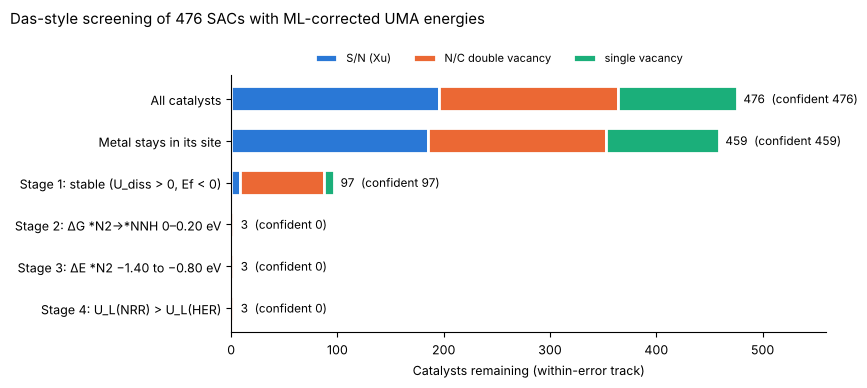

In [12]:
# stage-by-stage counts per family (the 'possible' track), plus the confident track
fig, ax = plt.subplots(figsize=(8.6, 3.9))
st = fun.stage.tolist()[::-1]; y = np.arange(len(st)); left = np.zeros(len(st))
for f, c in FAM.items():
    v = fun[f'possible {f}'].values[::-1]; ax.barh(y, v, left=left, color=c, height=0.6, edgecolor='white', linewidth=2, label=f); left += v
for yi, (pv, cv) in zip(y, zip(fun.possible.values[::-1], fun.confident.values[::-1])):
    ax.text(pv + 6, yi, f'{pv}  (confident {cv})', va='center', fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(st); ax.set_xlabel('Catalysts remaining (within-error track)'); ax.set_xlim(0, 560)
ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower center', bbox_to_anchor=(0.45, 1.0))
fig.suptitle('Das-style screening of 476 SACs with ML-corrected UMA energies', x=0.01, ha='left')
fig.tight_layout(); fig.savefig('fig_final_funnel.png', dpi=170); plt.show()

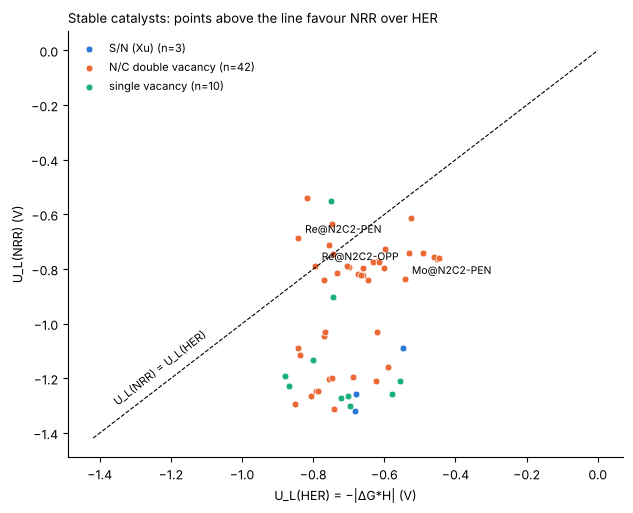

In [13]:
# NRR vs HER limiting potentials for the stable catalysts with a complete pathway
d = df[S1 & df.UL_NRR.notna() & df.UL_HER.notna()]
fig, ax = plt.subplots(figsize=(6.4, 5.2))
for f, c in FAM.items():
    s = d[d.family == f]; ax.scatter(s.UL_HER, s.UL_NRR, s=24, c=c, label=f'{f} (n={len(s)})', edgecolors='white', linewidths=0.5)
lo = min(d.UL_HER.min(), d.UL_NRR.min()) - 0.1
ax.plot([lo, 0], [lo, 0], 'k--', lw=0.8); ax.text(lo + 0.05, lo + 0.12, 'U_L(NRR) = U_L(HER)', fontsize=8, rotation=38)
for r in d[d.final_possible].itertuples():
    ax.annotate(r.SAC, (r.UL_HER, r.UL_NRR), xytext=(5, 4), textcoords='offset points', fontsize=7.5)
ax.set_xlabel('U_L(HER) = −|ΔG*H| (V)'); ax.set_ylabel('U_L(NRR) (V)'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Stable catalysts: points above the line favour NRR over HER', loc='left', fontsize=9.5)
fig.tight_layout(); fig.savefig('fig_NRR_vs_HER.png', dpi=170); plt.show()

In [14]:
out = df[['SAC', 'Metal', 'Support', 'family', 'vacancy', 'CN', 'n_N', 'n_S', 'n_C', 'status_bare', 'Ef_cal', 'U_diss_cal', 'stability',
          'dG_N2_to_NNH_end', 'step1_ml', 'dE_N2_end', 'dEN2_ml', 'dG_H*', 'dGH_ml', 'UL_NRR', 'path', 'PDS', 'UL_HER', 'final_confident', 'final_possible']]
out = out.rename(columns={'dG_N2_to_NNH_end': 'step1_UMA_raw', 'dE_N2_end': 'dEN2_UMA_raw', 'dG_H*': 'dGH_UMA_raw'})
out.round(4).to_csv('screening_476_final.csv', index=False)
models = pd.concat([resA, resB, resC]); models.round(3).to_csv('delta_model_cv.csv', index=False)
print('saved screening_476_final.csv, final_candidates.csv, delta_model_cv.csv and 4 figures')

saved screening_476_final.csv, final_candidates.csv, delta_model_cv.csv and 4 figures
